# Start Here

These notebooks show what a TypeScript notebook in Ganymede can do. Each
one runs on the TypeScript kernel the app runs itself, so they need no
server, only a network connection for the ones that load packages or data.

They were saved with their outputs, so you can read them before running
anything. Select a code cell and press **Shift-Enter** to run it, or use
**Run All**. Change anything: these are your copies.

| Notebook | What it shows |
| :--- | :--- |
| 01 Start Here | Cells, state, and the kinds of output a cell can show |
| 02 Web APIs | `fetch` from public APIs, tables, progress that updates in place |
| 03 Charts and Diagrams | `jupyter.chart` with Vega-Lite and Observable Plot, d3, Graphviz |
| 04 DuckDB | SQL in the notebook with `jupyter.sql`, results as tables and charts |
| 05 Generative Art | Seeded randomness, canvas and SVG, animation |
| 06 Widgets | Sliders and buttons that talk to the kernel |
| 07 UI Frameworks | React, Preact and Lit components as output |
| 08 Device | The `device` API: clipboard, haptics, dialogs, share and files |

## Cells keep their state

A cell's top-level declarations stay defined for the cells after it. The
last expression is the cell's result.

In [1]:
const moons = [
  { name: "Io", radiusKm: 1821.6, orbitDays: 1.769 },
  { name: "Europa", radiusKm: 1560.8, orbitDays: 3.551 },
  { name: "Ganymede", radiusKm: 2634.1, orbitDays: 7.155 },
  { name: "Callisto", radiusKm: 2410.3, orbitDays: 16.689 },
];
moons.map(m => m.name);

[ 'Io', 'Europa', 'Ganymede', 'Callisto' ]

TypeScript types are stripped before a cell runs, so annotate as much or as
little as you like. `await` works at the top level.

In [2]:
type Moon = (typeof moons)[number];
const largest = (list: Moon[]): Moon => list.reduce((a, b) => (b.radiusKm > a.radiusKm ? b : a));
await new Promise(resolve => setTimeout(resolve, 200));
console.log(`The largest moon is ${largest(moons).name}.`);

The largest moon is Ganymede.


## Rich output

The kernel's `jupyter` object turns values into rich output. `jupyter.table`
shows rows as a table: click a column's name to sort by it.

In [3]:
jupyter.table(moons, { title: "Galilean moons" });

namestring,radiusKmnumber,orbitDaysnumber
Io,1821.6,1.769
Europa,1560.8,3.551
Ganymede,2634.1,7.155
Callisto,2410.3,16.689


`jupyter.md` shows Markdown, math included.

In [4]:
jupyter.md`Kepler's third law: the square of the period grows with the cube of the orbit, $T^2 \propto a^3$.
Callisto's period is ${(moons[3].orbitDays / moons[0].orbitDays).toFixed(1)} times Io's.`;

Kepler's third law: the square of the period grows with the cube of the orbit, $T^2 propto a^3$.
Callisto's period is 9.4 times Io's.

`jupyter.svg` draws with no library at all.

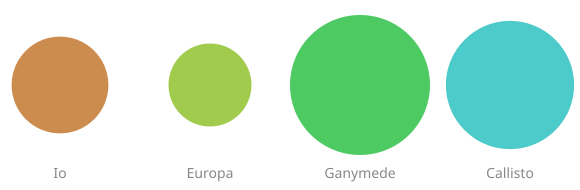

In [5]:
const scale = 70 / largest(moons).radiusKm;
const circles = moons.map((m, i) => {
  const x = 60 + i * 150;
  const r = m.radiusKm * scale;
  return `<circle cx="${x}" cy="85" r="${r.toFixed(1)}" fill="hsl(${30 + i * 50} 55% 55%)"/>
    <text x="${x}" y="178" text-anchor="middle" font-size="14" fill="currentColor">${m.name}</text>`;
});
jupyter.svg`<svg xmlns="http://www.w3.org/2000/svg" width="580" height="190" font-family="system-ui" style="color: #888">${circles.join("")}</svg>`;

`jupyter.html` shows HTML. Scripts in it run in a sandboxed frame once the
notebook is trusted.

In [6]:
jupyter.html`<details open>
  <summary><b>Galilean moons</b></summary>
  <p>Discovered by Galileo Galilei in January 1610.</p>
  <ul>${moons.map(m => `<li>${m.name}</li>`).join("")}</ul>
</details>`;

Galilean moons 
 Discovered by Galileo Galilei in January 1610. 
 Io Europa Ganymede Callisto

A plain object shows as text. To pick the output type yourself, display a
MIME bundle with `raw: true`; JSON shows as a tree you can fold.

In [7]:
await jupyter.display({ "application/json": { moons }, "text/plain": JSON.stringify(moons) }, { raw: true });

[{"name":"Io","radiusKm":1821.6,"orbitDays":1.769},{"name":"Europa","radiusKm":1560.8,"orbitDays":3.551},{"name":"Ganymede","radiusKm":2634.1,"orbitDays":7.155},{"name":"Callisto","radiusKm":2410.3,"orbitDays":16.689}]

## Output that updates

`jupyter.display` shows output while the cell is still running. Give it a
`display_id`, and a later display with `update: true` replaces it.

In [8]:
const sleep = (ms: number) => new Promise(resolve => setTimeout(resolve, ms));
const bar = (pct: number) => jupyter.html`<progress value="${pct}" max="100"></progress> ${pct}%`;
await jupyter.display(bar(0), { display_id: "progress" });
for (let pct = 10; pct <= 100; pct += 10) {
  await sleep(150);
  await jupyter.display(bar(pct), { display_id: "progress", update: true });
}

100%

## Errors

An exception stops the cell and shows where it was thrown.

In [9]:
JSON.parse("{ not json");

SyntaxError: Expected property name or '}' in JSON at position 2 (line 1 column 3)

## Packages

`import` loads packages from npm through the esm.sh CDN on first use; pin
a version with `npm:name@version`.

In [10]:
import { formatDistanceToNow } from "npm:date-fns@4";
const discovered = new Date("1610-01-07");
`Ganymede was discovered ${formatDistanceToNow(discovered)} ago.`;

'Ganymede was discovered almost 417 years ago.'

## Where to go next

Open **02 Web APIs** in the sidebar. The
[cdp-kernel docs](https://github.com/tlockney/cdp-kernel/blob/main/docs/jupyter-api.md)
describe everything `jupyter` offers.